![Banner](../images/06_poisson_kriging.png)

# Poisson Kriging



Ordinary kriging answers a question about a variable measured at points. At a place you did not sample, it returns the linear unbiased estimate of that variable, and the error variance of that estimate, from a single variogram. A disease map asks that question about a count. The observation is a number of cases over a population at risk, published as a rate for a county, a census tract, or a year of that county. A county of a few thousand residents produces a far noisier rate than a county of a million, at the same underlying risk.

This notebook is the map for the three Poisson-kriging families in GeoLattice. Centroid Poisson kriging keeps the ordinary-kriging system and adds a population term on the diagonal. Area-to-area and area-to-point Poisson kriging replace the point covariances with averages over the people inside each polygon. Poisson cokriging stacks several correlated counts into one system. Spatio-temporal Poisson kriging gives the covariance a spatial lag and a temporal lag. The notebook writes that shared system, then runs centroid Poisson kriging on twelve counties and one target. The three notebooks that follow keep one family each and carry it through a disease dataset.

Four notebooks estimate a disease rate from counts and population, so a small county does not dominate the map.

- **Poisson Kriging.** This notebook. The shared system, and centroid Poisson kriging on twelve counties and one target.
- **Poisson Kriging of Areal Disease Data.** 217 counties of Northeastern US breast-cancer mortality. Census point support, a deconvolved point-support variogram, area-to-area and area-to-point maps, and a coherence check.
- **Multivariate Poisson Cokriging.** A linear model of coregionalization, a four-disease simulation, then Northeast diabetes with physical inactivity and obesity as auxiliaries.
- **Spatio-Temporal Poisson Kriging.** Atlantic lung and bronchus cancer, 666 counties over 15 years, a fitted metric space-time variogram, 60 held-out counties, and a forecast one year past the panel.

Library: `geolattice.geostatistics`



## Table of Contents

- [What this chapter covers](#what-this-chapter-covers)
1. [Notebooks in this chapter](#1-notebooks-in-this-chapter)
2. [How Poisson kriging works](#2-how-poisson-kriging-works)
    - 2.1 [The Poisson reliability term](#the-poisson-reliability-term)
    - 2.2 [Centroid, area-to-area, and area-to-point](#centroid-area-to-area-and-area-to-point)
    - 2.3 [The population-weighted variogram](#the-population-weighted-variogram)
    - 2.4 [Poisson cokriging](#poisson-cokriging)
    - 2.5 [A year on the same counties](#a-year-on-the-same-counties)
    - 2.6 [A local neighborhood](#a-local-neighborhood)
3. [Poisson kriging in GeoLattice](#poisson-kriging-in-geolattice)
4. [Python setup](#python-setup)
5. [Twelve counties and one target](#twelve-counties-and-one-target)
6. [How to read the estimate](#how-to-read-the-estimate)
7. [Where the next notebooks go](#where-the-next-notebooks-go)
8. [Resources](#resources)
    - 8.1 [The paper behind each estimator](#the-paper-behind-each-estimator)
    - 8.2 [Textbooks that cover the kriging system](#textbooks-that-cover-the-kriging-system)
    - 8.3 [In this library](#in-this-library)


## Overview

Write the ordinary-kriging predictor at an unsampled location $\mathbf{u}_0$ as

$$
\hat Z(\mathbf{u}_0) = \sum_{i=1}^{n} \lambda_i \, Z(\mathbf{u}_i),
$$

with weights from the system in the [kriging introduction](../05_02_kriging/05_02_00_introduction_kriging.ipynb):

$$
\begin{bmatrix}
\mathbf{C} & \mathbf{1} \\
\mathbf{1}^{\top} & 0
\end{bmatrix}
\begin{bmatrix}
\boldsymbol{\lambda} \\
\mu
\end{bmatrix}
=
\begin{bmatrix}
\mathbf{c}_0 \\
1
\end{bmatrix}.
$$

$\mathbf{C}$ holds covariances among the samples, $\mathbf{c}_0$ holds covariances between the samples and the target, and $\mu$ enforces $\sum \lambda_i = 1$ so an unknown constant mean cancels. The kriging variance is $C(0) - \boldsymbol{\lambda}^{\top}\mathbf{c}_0 - \mu$.

A disease rate is a different observation. Let area $v_i$ have population $n_i$ and count $d_i$. The latent **risk** $R(v_i)$ is the intensity of a Poisson count,

$$
d_i \sim \mathrm{Poisson}\big(n_i \, R(v_i)\big),
\qquad
z_i = B\,\frac{d_i}{n_i},
$$

where $B$ is the rate base (`rate_base`: $1$ for a proportion, $100$ for a percentage, $10^5$ for a rate per 100,000). Because a Poisson count has variance equal to its mean,

$$
\mathrm{Var}(z_i) = B\,\frac{m^\ast}{n_i},
\qquad
m^\ast = \frac{\sum_j n_j \, z_j}{\sum_j n_j}.
$$

$m^\ast$ is the population-weighted mean of the rates as they are stored. Equivalently, with $\bar R = m^\ast / B$ the mean per-person risk, the same variance is $B^2 \bar R / n_i$. A small $n_i$ makes a large variance. Ordinary kriging of $z$ reads every rate as a measurement of $R$ with one common noise level. Poisson kriging (Goovaerts, 2006) puts $\mathrm{Var}(z_i)$ on that area's diagonal, so the weight shrinks as the population shrinks.

### The Poisson reliability term

The predictor is still linear and unbiased,

$$
\hat R(\mathbf{u}_0) = \sum_{i=1}^{k} \lambda_i \, z_i,
\qquad
\sum_{i=1}^{k} \lambda_i = 1,
$$

and the weights solve

$$
\begin{bmatrix}
\mathbf{C} + B\,\mathrm{diag}\!\left(\dfrac{m^\ast}{n_i}\right) & \mathbf{1} \\[6pt]
\mathbf{1}^{\top} & 0
\end{bmatrix}
\begin{bmatrix}
\boldsymbol{\lambda} \\
\mu
\end{bmatrix}
=
\begin{bmatrix}
\mathbf{c}_0 \\
1
\end{bmatrix}.
$$

The kriging variance keeps the ordinary-kriging form, $\sigma^2 = C(0) - \boldsymbol{\lambda}^{\top}\mathbf{c}_0 - \mu$. `PoissonKriging` returns the standard error $\sigma$.

In a local neighborhood the mean $m^\ast$ is the population-weighted mean of the $k$ neighbors that enter that system, which is what `_solve` computes. `rate_base` scales the diagonal onto the units of $z$. The class detects $B$ from the magnitude of the rates when `rate_base` is omitted. Pass it explicitly when the base is known. A per-100,000 rate with the diagonal left unscaled is short by about $10^5$, and the small counties keep too much weight.

The size of the term relative to the sill is the whole decision. On the twelve counties below, $C(0) = 81.5$. A population of 200,000 adds about 27 to the diagonal. A population of 4,000 adds about 1,350, roughly seventeen times the sill, and that rate almost drops out of the estimate.

### Centroid, area-to-area, and area-to-point

All three estimators in the [breast-cancer notebook](05_06_01_poisson_kriging_ata_atp.ipynb) are this system. They differ in the support of $C$.

**Centroid.** Each county is one point, its population-weighted centroid $\mathbf{u}_i$, with population $n_i$ and rate $z_i$. The covariance is the point covariance $C_R(\mathbf{u}_i - \mathbf{u}_j)$. This is `PoissonKriging`. It is the call in the worked example. The size and shape of the polygon stay outside the covariance.

**Area-to-area (ATA).** Point covariances are replaced by block covariances averaged over the census points inside the two counties, weighted by population,

$$
\bar C_R(v_i, v_j)
= \frac{\sum_{s \in v_i}\sum_{s' \in v_j} n_s \, n_{s'} \, C(\mathbf{u}_s - \mathbf{u}_{s'})}
{\sum_{s \in v_i}\sum_{s' \in v_j} n_s \, n_{s'}}.
$$

This is `AreaPoissonKriging.predict_area`. Averaging over the polygon filters short-range variance, and the kriging variance usually falls relative to the centroid estimator. `PointSupport` holds the census points grouped by county.

**Area-to-point (ATP).** The left-hand side stays the area-to-area matrix. The right-hand side becomes the covariance between each county and one target point $\mathbf{u}_s$,

$$
\bar C_R(v_i, \mathbf{u}_s)
= \frac{\sum_{s' \in v_i} n_{s'} \, C(\mathbf{u}_{s'} - \mathbf{u}_s)}{\sum_{s' \in v_i} n_{s'}}.
$$

`AreaPoissonKriging.predict_points` evaluates that system on a grid and returns a continuous surface. The population-weighted average of the point estimates inside a county recovers the area-to-area estimate of that county (the coherence constraint). The breast-cancer notebook checks the identity to machine precision.

### The population-weighted variogram

The kriging engine consumes a point-support covariance of the risk. The rates that are observed are noisy and, for ATA and ATP, areal. Two steps sit in front of the solve. Both are worked on the breast-cancer counties. This notebook sets the variogram by hand, the same device as the kriging introduction.

The **population-weighted risk semivariogram** (Monestiez et al., 2006) down-weights pairs whose populations are small and subtracts the Poisson noise, so the sill is the variance of $R$ and the sampling variance stays on the kriging diagonal where it belongs:

$$
\hat\gamma_R(h)
= \frac{1}{2\sum_{\alpha \in N(h)} w_\alpha}
\sum_{\alpha \in N(h)} w_\alpha \Big[(z_\alpha - z_{\alpha+h})^2 - m^\ast\Big],
\qquad
w_\alpha = \frac{n_\alpha \, n_{\alpha+h}}{n_\alpha + n_{\alpha+h}}.
$$

Distances between counties are the population-weighted distances between their census-point clouds.

**Deconvolution** recovers the point-support model from that areal semivariogram. Regularisation relates the two by

$$
\gamma_v(h) = \bar\gamma(v, v_h) - \bar\gamma(v, v),
$$

and the breast-cancer notebook inverts the relation iteratively with the same block-semivariance helpers the kriging engine uses. The point-support sill comes out higher than the areal sill: change of support had averaged that variance away, and ATP needs it back.

### Poisson cokriging

One disease is often a thin signal. Physical inactivity and obesity move with diabetes across counties; several rare counts can share a spatial pattern. **Poisson cokriging** (Payares-Garcia, Osei, Mateu & Stein, 2024) keeps a Poisson variance for every count and couples the risks with a linear model of coregionalization.

For diseases $\ell, \kappa$ the direct and cross semivariograms use the same pair weights $w_{ij} = n_i n_j / (n_i + n_j)$, with a noise term subtracted so the sill is the covariance of the risks. An LMC writes every covariance as one basic structure times a coregionalization matrix,

$$
C_{\ell\kappa}(h) = b_{\ell\kappa}\, g(h),
$$

where $g(0) = 1$ and $B = [b_{\ell\kappa}]$ is symmetric positive semidefinite. `fit_lmc` estimates $B$ by weighted least squares and projects it onto the nearest positive-semidefinite matrix. The module fits one exponential or one spherical structure. A nested exponential-plus-spherical LMC is the form in the paper; one structure is the form `LMC` stores.

The target risk is a linear combination of every disease's rates. The target disease has weights that sum to 1. Each auxiliary has weights that sum to 0, the usual cokriging constraint that keeps an auxiliary from shifting the mean:

$$
\hat R_t(s_0) = \sum_{\ell=1}^{P} \sum_{i=1}^{k_\ell} \lambda_\ell(s_i)\, z_\ell(s_i),
\qquad
\sum_i \lambda_t(s_i) = 1,
\qquad
\sum_i \lambda_\ell(s_i) = 0 \quad (\ell \neq t).
$$

The block diagonal carries the Poisson terms. On a direct block the addition is $m^\ast_\ell / n_i$ in the units of that disease's rate. On a cross block, at a county where both diseases are observed, the addition is the mean shared risk over $n_i$. `poisson_cokrige` builds and solves that system. With one disease it reduces to univariate Poisson kriging (`poisson_krige`). With the prediction locations equal to the data locations and each county removed in turn, the same call smooths the observed rates.

The [cokriging notebook](05_06_02_poisson_cokriging.ipynb) fits the LMC on a simulation where the true risk is known, then on Northeast diabetes with inactivity and obesity as the auxiliaries.

### A year on the same counties

A panel observes the same counties every year. The predictor keeps the Poisson diagonal and replaces $C(h)$ with a covariance of a joint lag. The model used in this chapter is the **metric** model from the [spatio-temporal introduction](../05_05_spatial_temporal_kriging/05_05_00_spatial_temporal_kriging.ipynb):

$$
h_{st} = \sqrt{h_s^2 + (a \, h_t)^2},
\qquad
C(h_s, h_t) = C(h_{st}).
$$

The anisotropy $a$ (`stAni`) converts a time lag into the units of the map. `vgm` builds the joint variogram. `vgm_st("metric", joint=..., st_ani=a)` wraps it. `empirical_st_variogram` and `fit_metric_st_variogram` estimate that model from a complete county-by-year matrix. `vgm_st` also builds `separable`, `productSum`, `sumMetric`, and `simpleSumMetric` when the spatial range and the temporal range should be separate parameters.

`STPoissonKriging` solves the centroid system on the $k$ nearest area-years in the scaled coordinates $(x, y, a \cdot t)$:

$$
\sum_j \lambda_j \Big[C\big((\mathbf{u}_i, t_i) - (\mathbf{u}_j, t_j)\big) + \delta_{ij}\, B\,\frac{m^\ast}{n_i}\Big] + \mu
= C\big((\mathbf{u}_i, t_i) - (\mathbf{u}_0, t_0)\big).
$$

One time stamp per area returns centroid Poisson kriging. Equal populations return space-time ordinary kriging. The [Atlantic notebook](05_06_03_poisson_kriging_st.ipynb) fits the metric model to lung-cancer mortality, 1998-2012, holds out 60 counties, and forecasts one year past the last observed year.

### A local neighborhood

Solving against every training row scales as $O(N^3)$. `PoissonKriging.predict` and `STPoissonKriging.predict` build each prediction from its $k$ nearest neighbors and stack those systems into one batched solve of shape `(n_pred, k+1, k+1)`: NumPy on CPU, CuPy on GPU (`use_gpu`). `poisson_cokrige(..., number_of_neighbors=k)` stacks systems of shape `(n_pred, P k + P, P k + P)`. The worked example uses `use_gpu=False`.

`predict_id` is leave-one-out of one stored area, and it stays on CPU. Area-to-area and area-to-point covariances are block averages, and they stay on CPU as well. The three case-study notebooks time the batched path on a national county set.


---

## Poisson kriging in GeoLattice

| Object | Call |
|---|---|
| `PoissonKriging` | `fit(coords, values, populations, ids=...)` then `predict(X_pred, number_of_neighbors)` or `predict_id(area_id)` |
| `AreaPoissonKriging` | `fit(point_support, block_values)` then `predict_area(area_id)` or `predict_points(area_id, targets=...)` |
| `PointSupport` | Census points grouped by areal unit. `from_geodataframes` builds it from a point layer and a polygon layer |
| `pck_variogram`, `pck_crossvariogram` | Population-weighted direct and cross semivariograms of the counts |
| `fit_lmc`, `LMC` | One exponential or spherical structure and a positive-semidefinite coregionalization matrix $B$ |
| `poisson_cokrige` | $P$-variate Poisson cokriging. `number_of_neighbors` and `use_gpu` select the batched solve. `smooth=True` is leave-one-out |
| `poisson_krige` | The one-disease case of the same system |
| `STPoissonKriging` | `fit(coords, times, values, populations, ids=...)` then `predict(coords, times, number_of_neighbors)` |
| `vgm`, `vgm_st` | The joint variogram, and one of `metric`, `separable`, `productSum`, `sumMetric`, `simpleSumMetric` |
| `empirical_st_variogram`, `fit_metric_st_variogram` | The Matheron cloud on a complete panel, and the metric fit |

The variogram object passed to `PoissonKriging` and `AreaPoissonKriging` exposes `fitted_params = [nugget, partial_sill, range]` and is callable as $\gamma(h)$. A fitted `Variogram` is that object. The class below is the same contract, with the parameters set from the generating risk so the weights are the solution of a known system.

`use_gpu` is `'auto'` (GPU when CuPy can run a kernel, otherwise CPU), `True`, or `False`. `use_gpu=False` in the example keeps the arithmetic on NumPy.


---

## Python setup


**Installation.** This notebook needs installation option 4 (core, spatial analysis, spatial statistics and geostatistics): `pip install "geolattice[geostats]"`. See "Installation options" in the GeoLattice README.

In [1]:
%matplotlib inline
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")

import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import geolattice.geostatistics as gstat
from geolattice.geostatistics import PoissonKriging

USE_GPU = False  # identical arithmetic on CPU and GPU machines

print(f"geolattice.geostatistics : {gstat.__version__}")


geolattice.geostatistics : 0.3.49


---

## Twelve counties and one target

The generating risk is linear in easting, $R = 40 + 0.35\, x$, in deaths per 100,000. Eleven counties have population 200,000 and report $R$. County C6, at $(18, 55)$, has population 4,000. Its generating risk is 46.3. The rate on the file is 160, the kind of spike a handful of cases produces in a small population. The target is the unsampled location $(30, 62)$, where the generating risk is 50.5.

The semivariogram is spherical with nugget 0, partial sill equal to the variance of the twelve generating risks, and range 80 km. Every one of the eight neighbors used below lies inside that range.


In [2]:
class Spherical:
    # fitted_params = [nugget, partial sill, range]; __call__ returns gamma(h).

    def __init__(self, nugget, psill, rng):
        self.fitted_params = [float(nugget), float(psill), float(rng)]

    def __call__(self, h):
        h = np.asarray(h, dtype=float)
        n, ps, r = self.fitted_params
        hr = h / r
        g = np.where(h <= r, ps * (1.5 * hr - 0.5 * hr ** 3), ps)
        return n + np.where(h == 0, 0.0, g)

counties = pd.DataFrame({
    "id": [f"C{i}" for i in range(1, 13)],
    "x": [10, 30, 50, 70, 90, 18, 42, 62, 85, 25, 55, 80],
    "y": [20, 25, 18, 22, 28, 55, 60, 52, 58, 85, 80, 88],
})
counties["risk"] = 40 + 0.35 * counties["x"]
counties["pop"] = 200_000
counties.loc[counties["id"] == "C6", "pop"] = 4_000
counties["rate"] = counties["risk"]
counties.loc[counties["id"] == "C6", "rate"] = 160.0

target = np.array([[30.0, 62.0]])
true_target = 40 + 0.35 * 30.0

psill = float(np.var(counties["risk"].to_numpy()))
variogram = Spherical(0.0, psill, 80.0)

print(f"partial sill  : {psill:.3f}")
print(f"target risk   : {true_target:.1f}")
counties.round(2)


partial sill  : 81.492
target risk   : 50.5


,id,x,y,risk,pop,rate
0,C1,10,20,43.50,200000,43.50
1,C2,30,25,50.50,200000,50.50
2,C3,50,18,57.50,200000,57.50
3,C4,70,22,64.50,200000,64.50
4,C5,90,28,71.50,200000,71.50
5,C6,18,55,46.30,4000,160.00
6,C7,42,60,54.70,200000,54.70
7,C8,62,52,61.70,200000,61.70
8,C9,85,58,69.75,200000,69.75
9,C10,25,85,48.75,200000,48.75


Two fits share that variogram and those rates. The first uses the populations on the file. The second sets every population to 200,000, so C6 carries the same reliability term as a large county. Both predictions use the eight nearest centroids. Leave-one-out then hides C6, and hides C7, and predicts each from the other counties.


In [3]:
xy = counties[["x", "y"]].to_numpy()
rates = counties["rate"].to_numpy()
ids = counties["id"].to_numpy()

pk = PoissonKriging(variogram, rate_base=100_000, use_gpu=USE_GPU).fit(
    xy, rates, counties["pop"].to_numpy(), ids=ids
)
z_pk, se_pk = pk.predict(target, number_of_neighbors=8)

pop_large = np.full(len(counties), 200_000.0)
pk_large = PoissonKriging(variogram, rate_base=100_000, use_gpu=USE_GPU).fit(
    xy, rates, pop_large, ids=ids
)
z_large, se_large = pk_large.predict(target, number_of_neighbors=8)

loo_c6 = pk.predict_id("C6", number_of_neighbors=8)
loo_c7 = pk.predict_id("C7", number_of_neighbors=8)

summary = pd.DataFrame([
    {"estimate": "Generating risk", "value": true_target, "std_error": np.nan},
    {"estimate": "Poisson kriging", "value": z_pk[0], "std_error": se_pk[0]},
    {"estimate": "Every county at 200,000", "value": z_large[0], "std_error": se_large[0]},
    {"estimate": "Leave-one-out C6", "value": loo_c6["zhat"], "std_error": loo_c6["sig"]},
    {"estimate": "Leave-one-out C7", "value": loo_c7["zhat"], "std_error": loo_c7["sig"]},
])
summary.round(3)


,estimate,value,std_error
0,Generating risk,50.500,NaN
1,Poisson kriging,54.412,5.986
2,"Every county at 200,000",86.867,5.435
3,Leave-one-out C6,50.246,7.184
4,Leave-one-out C7,57.711,6.569


,id,km,pop,risk,rate
6,C7,12.17,200000,54.70,54.70
5,C6,13.89,4000,46.30,160.00
9,C10,23.54,200000,48.75,48.75
10,C11,30.81,200000,59.25,59.25
7,C8,33.53,200000,61.70,61.70
1,C2,37.00,200000,50.50,50.50
0,C1,46.52,200000,43.50,43.50
2,C3,48.33,200000,57.50,57.50


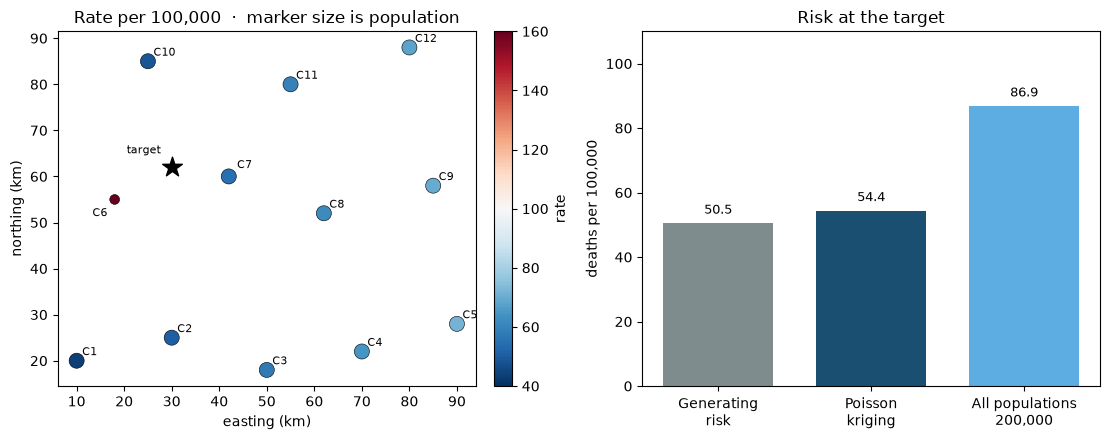

In [4]:
from scipy.spatial.distance import cdist

dist = cdist(target, xy)[0]
nearest = counties.assign(km=dist).sort_values("km").head(8)

fig, ax = plt.subplots(1, 2, figsize=(11.2, 4.5))

sizes = 50 + 40 * np.log10(counties["pop"] / 4_000)
sc = ax[0].scatter(
    counties["x"], counties["y"], c=counties["rate"], s=sizes,
    cmap="RdBu_r", vmin=40, vmax=160, edgecolor="k", linewidth=0.4, zorder=3,
)
label_at = {"C6": (-16, -12), "C7": (6, 6)}
for _, row in counties.iterrows():
    ax[0].annotate(
        row["id"], (row["x"], row["y"]), textcoords="offset points",
        xytext=label_at.get(row["id"], (4, 4)), fontsize=8,
    )
ax[0].scatter(target[0, 0], target[0, 1], marker="*", s=220, c="k", zorder=4)
ax[0].annotate("target", (target[0, 0], target[0, 1]), textcoords="offset points",
               xytext=(-8, 10), fontsize=8, ha="right")
ax[0].set_xlabel("easting (km)")
ax[0].set_ylabel("northing (km)")
ax[0].set_title("Rate per 100,000  ·  marker size is population")
fig.colorbar(sc, ax=ax[0], fraction=0.046, pad=0.04, label="rate")

labels = ["Generating\nrisk", "Poisson\nkriging", "All populations\n200,000"]
values = [true_target, z_pk[0], z_large[0]]
bars = ax[1].bar(labels, values, color=["#7f8c8d", "#1b4f72", "#5dade2"], width=0.72)
ax[1].set_ylabel("deaths per 100,000")
ax[1].set_title("Risk at the target")
ax[1].set_ylim(0, 110)
for bar, val in zip(bars, values):
    ax[1].text(bar.get_x() + bar.get_width() / 2, val + 2, f"{val:.1f}",
               ha="center", va="bottom", fontsize=9)

fig.tight_layout()
nearest[["id", "km", "pop", "risk", "rate"]].round(2)


---

## How to read the estimate

The partial sill is $81.492$, the variance of the twelve generating risks, and the nugget is $0$, so $C(0) = 81.492$. The range is $80$ km. `number_of_neighbors=8` and `rate_base=100000`.

The eight nearest centroids to $(30, 62)$ are C7 at $12.17$ km (rate $54.70$, population $200{,}000$), C6 at $13.89$ km (rate $160$, population $4{,}000$), then C10, C11, C8, C2, C1, and C3, the last of them at $48.33$ km. All eight sit inside the range. The population-weighted mean rate of those eight neighbors is $m^\ast = 54.003$. The diagonal addition is $B m^\ast / n$:

$$
\frac{100{,}000 \times 54.003}{4{,}000} = 1{,}350
\quad\text{at C6},
\qquad
\frac{100{,}000 \times 54.003}{200{,}000} = 27.00
\quad\text{at a large county}.
$$

$1{,}350$ is about seventeen times the sill, so C6's covariance with the target barely survives the penalty. $27$ is about a third of the sill, so a large county keeps the weight its distance would give it under ordinary kriging.

**Poisson kriging at the target is $54.412$, with standard error $5.986$.** The generating risk there is $50.5$. C7, the nearest large county, reports $54.70$, and the estimate sits with that neighbor. The spike of $160$ at C6, $13.9$ km away, does not pull it.

**The same system with every population set to $200{,}000$ returns $86.867$, with standard error $5.435$.** C6 now carries a diagonal addition of $27$, the same term as its neighbors, and the rate $160$ takes a share of the weight. The estimate moves from $54.4$ toward $160$. The two standard errors are close because both are functions of the same covariance geometry; the population term changes the weights, and the variance moves with them.

**Leave-one-out at C6 is $50.246$, with standard error $7.184$.** The rate on the file is $160$. The generating risk is $46.3$. The smoothed value sits next to the risk, because the county is predicted from its neighbors and its own rate is excluded. That gap, from $160$ down to $50.2$, is the sampling noise the diagonal is built to filter when C6 is a neighbor of somewhere else.

**Leave-one-out at C7 is $57.711$, with standard error $6.569$.** C7 reports $54.70$ from a population of $200{,}000$, and the estimate stays beside that rate. The standard error is larger than the $5.986$ at the target: the target sits between C6 and C7, and the leave-one-out neighborhood has lost C7 itself.


---

## Where the next notebooks go

The call above is centroid Poisson kriging with a covariance that was set on twelve counties. What it leaves out is a real county geography, a variogram estimated from the rates, a change of support, a second disease, and a year index.

| Next notebook | What it adds to the call you just ran |
|---|---|
| [Area-to-area and area-to-point](05_06_01_poisson_kriging_ata_atp.ipynb) | 217 Northeastern-US counties, 5,419 census points in `PointSupport`, the population-weighted semivariogram, deconvolution to a point-support model, `AreaPoissonKriging` leave-one-out and a 12 km ATP grid, and the coherence check |
| [Poisson cokriging](05_06_02_poisson_cokriging.ipynb) | `pck_variogram` and `pck_crossvariogram`, `fit_lmc`, a simulation in which extra diseases cut the prediction error, and Northeast diabetes cokriged with inactivity and obesity |
| [Spatio-temporal Poisson kriging](05_06_03_poisson_kriging_st.ipynb) | 666 Atlantic counties by the years 1998-2012, `empirical_st_variogram` and `fit_metric_st_variogram`, `STPoissonKriging` on 60 held-out counties, and a forecast at 2013 |

Open the notebook whose question matches the table at the top. Each one assumes the ordinary-kriging system from the classic-kriging chapter and the one-section version of its own estimator written here.


---

## Resources

### The paper behind each estimator

| Reference | Estimator |
|---|---|
| Goovaerts, P. (2006). Geostatistical analysis of disease data: accounting for spatial support and population density in the isopleth mapping of cancer mortality risk using area-to-point Poisson kriging. *International Journal of Health Geographics* 5:52. | Centroid, area-to-area, and area-to-point Poisson kriging |
| Monestiez, P., Dubroca, L., Bonnin, E., Durbec, J.P. & Guinet, C. (2006). Geostatistical modelling of spatial uncertainty using Poisson kriging. *Ecological Modelling* 194, 233-243. | The population-weighted risk semivariogram |
| Goovaerts, P. (2008). Kriging and semivariogram deconvolution in the presence of irregular geographical units. *Mathematical Geosciences* 40, 101-128. | Areal-to-point deconvolution |
| Payares-Garcia, D., Osei, F., Mateu, J. & Stein, A. (2024). Multivariate Poisson cokriging: a geostatistical model for health count data. *Statistical Methods in Medical Research* 33(10), 1637-1656. | `poisson_cokrige` and the LMC |
| Pebesma, E. (2012). spacetime: Spatio-Temporal Data in R. *Journal of Statistical Software* 51(7). | The metric space-time model. `STPoissonKriging` uses the same joint distance |

### Textbooks that cover the kriging system

| Reference | What to read it for |
|---|---|
| Goovaerts, P. (1997). *Geostatistics for Natural Resources Evaluation*. Oxford University Press. | Ordinary kriging, block kriging, and change of support |
| Chilès, J.-P. & Delfiner, P. (2012). *Geostatistics: Modeling Spatial Uncertainty* (2nd ed.). Wiley. | The kriging system, regularisation, and multivariate covariance |
| Cressie, N. & Wikle, C.K. (2011). *Statistics for Spatio-Temporal Data*. Wiley. | Space-time covariance models |

### In this library

| Object | Role |
|---|---|
| `PoissonKriging` | Centroid Poisson kriging. `fit` stores the areas; `predict` returns the estimate and the standard error; `predict_id` is leave-one-out |
| `AreaPoissonKriging` | Area-to-area and area-to-point Poisson kriging |
| `PointSupport` | Population points grouped by areal unit |
| `poisson_cokrige`, `poisson_krige` | $P$-variate Poisson cokriging, and the one-disease case |
| `pck_variogram`, `pck_crossvariogram`, `fit_lmc`, `LMC` | Population-weighted semivariograms and the coregionalization matrix |
| `STPoissonKriging` | Space-time Poisson kriging of areal rates |
| `vgm`, `vgm_st`, `empirical_st_variogram`, `fit_metric_st_variogram` | The space-time covariance `STPoissonKriging` consumes |
| `OrdinaryKriging`, `STKriging` | The linear reference, and space-time ordinary kriging of point data, from the earlier chapters |
